# Restauracje w NYC – źródła danych i ocena jakości

- **DOHMH Restaurant Inspection Results** (`43nn-pn8j`) – wyniki kontroli sanitarnych,
- **311 Restaurant data** (`jrsc-cabt`) – zgłoszenia mieszkańców dotyczące restauracji.

### Opis źródeł

**Kontrole sanitarne (DOHMH)**
- Zbiór zawiera wszystkie naruszenia stwierdzone podczas kontroli restauracji i stołówek uczelnianych: utrzymane po odwołaniu lub jeszcze nierozstrzygnięte. Jeden wiersz to jedno naruszenie. Kontrole bez naruszeń i restauracje jeszcze niekontrolowane też mają swój wiersz.
- **Zbiór nie jest pełnym archiwum.** Dla każdej restauracji publikowane są tylko kontrole z **ok. 3 lat przed jej ostatnią kontrolą**, a starsze są usuwane.
- Zbiór obejmuje **tylko działające restauracje**. Po zamknięciu lokalu znika on ze zbioru razem z całą historią kontroli.
- Skutki: dane z kontroli są praktycznie kompletne dopiero od ok. 10.2023, a na trendzie liczby kontroli w czasie nie można polegać. Obraz jest też lekko „za dobry”, bo lokale z najgorszymi wynikami częściej są zamykane i znikają z danych.
- Dane pochodzą z kilku systemów administracyjnych, więc mogą zawierać braki i nielogiczne wartości (sprawdzane w sekcji 9).

**Zgłoszenia 311**
- Zbiór `jrsc-cabt` to widok pełnego rejestru 311 (`erm2-nwe9`) zawężony do zgłoszeń *Food Establishment*, obsługiwanych przez DOHMH. Zawiera zgłoszenia od 01.2020.
- Zgłoszenia nie są usuwane, więc ich liczba w czasie (trend, sezonowość) jest wiarygodna.
- Zgłoszenie to deklaracja mieszkańca, a nie potwierdzone naruszenie. Liczba zgłoszeń zależy też od gęstości lokali i liczby osób w okolicy.

Celem jest ocena, czy dane nadają się do analizy (zakres, braki, spójność, możliwość łączenia), oraz podjęcie decyzji o ich czyszczeniu.

## Słownik pojęć

**Instytucje i źródła**
- **DOHMH** – Department of Health and Mental Hygiene, miejski departament zdrowia NYC. Przeprowadza kontrole sanitarne i obsługuje zgłoszenia 311 dotyczące restauracji.
- **311** – miejska infolinia i system zgłoszeń dla mieszkańców. Każde zgłoszenie to osobny rekord (*service request*).
- **NYC Open Data / SODA API** – portal, z którego pobieramy oba zbiory.

**Pojęcia analityczne używane w notatniku**
- **Restauracja** – jeden lokal identyfikowany przez `camis`.
- **Kontrola** – jedna wizyta inspektora w restauracji w danym dniu (`camis` + `inspection_date`). Kończy się jednym wynikiem punktowym i ewentualnie oceną.
- **Naruszenie** – pojedyncza nieprawidłowość stwierdzona podczas kontroli. Jedna kontrola może mieć wiele naruszeń.
- **Zgłoszenie 311** – jedna skarga mieszkańca dotycząca lokalu gastronomicznego.
- **Wspólny okres** – przedział dat, w którym mamy dane z obu źródeł. Tylko w nim porównujemy kontrole ze zgłoszeniami.
- **Czas obsługi** – liczba dni od utworzenia do zamknięcia zgłoszenia (`closed_date − created_date`).
- **Dopasowanie** – przypisanie zgłoszenia 311 do konkretnej restauracji po adresie lub po najbliższym punkcie na mapie.
- **Borough** – jedna z 5 dzielnic NYC: Manhattan, Brooklyn, Queens, Bronx, Staten Island.
- **ZIP** – 5-cyfrowy kod pocztowy. Kody NYC zaczynają się od 100–104 oraz 110–116, a 07xxx to New Jersey.

**Pola zbioru inspekcji**
- **`camis`** – unikalny, stały identyfikator restauracji w systemie DOHMH. To klucz restauracji.
- **`dba`** – *doing business as*, nazwa handlowa lokalu. Nie jest unikalna, np. sieciówki mają wiele lokali o tej samej nazwie.
- **`boro`, `building`, `street`, `zipcode`** – dzielnica i adres lokalu. `boro = '0'` oznacza brak dzielnicy.
- **`cuisine_description`** – typ kuchni deklarowany przez lokal.
- **`inspection_date`** – data kontroli. Wartość `1900-01-01` oznacza restaurację, która nie miała jeszcze kontroli.
- **`inspection_type`** – rodzaj kontroli w formacie *program / etap*:
  - programy: *Cycle Inspection* (rutynowa kontrola cykliczna), *Pre-permit* (przed wydaniem zezwolenia), *Administrative*, *Inter-Agency Task Force* oraz kontrole tematyczne, np. *Smoke-Free Air Act*, *Calorie Posting*, *Trans Fat*;
  - etapy: *Initial* (pierwsza kontrola), *Re-inspection* (ponowna kontrola po złym wyniku), *Reopening* (przed ponownym otwarciem zamkniętego lokalu), *Compliance* (sprawdzenie usunięcia konkretnych uchybień).
- **`action`** – działanie po kontroli, np. stwierdzono naruszenia, brak naruszeń, zamknięcie lokalu, ponowne otwarcie.
- **`violation_code` / `violation_description`** – kod i opis naruszenia. Cyfry oznaczają kategorię (np. 02 – temperatura żywności, 04 – szkodniki i skażenie, 06 – higiena i ochrona żywności, 08 – utrzymanie lokalu i ochrona przed szkodnikami, 10 – instalacje i wyposażenie), a litera konkretne naruszenie.
- **`critical_flag`** – *Critical*: naruszenie, które może bezpośrednio prowadzić do choroby przenoszonej przez żywność; *Not Critical*: pozostałe; *Not Applicable*: wiersz bez naruszenia.
- **`score`** – suma punktów karnych za naruszenia stwierdzone podczas kontroli. **Im wyższy wynik, tym gorzej**, a 0 oznacza brak naruszeń.
- **`grade`** – ocena literowa wywieszana na drzwiach lokalu:
  - **A** – 0–13 pkt, **B** – 14–27 pkt, **C** – 28 pkt i więcej;
  - **N** – jeszcze nie oceniono, **Z** – ocena w toku (lokal może ją zakwestionować), **P** – ocena w toku po ponownym otwarciu lokalu zamkniętego po kontroli;
  - ocenę A lokal dostaje od razu przy pierwszej kontroli cyklicznej. Przy gorszym wyniku ocena (B lub C) przyznawana jest dopiero po re-inspekcji. Dlatego wiele kontroli nie ma oceny.
- **`grade_date`** – data przyznania oceny; **`record_date`** – data wygenerowania zbioru (identyczna dla prawie wszystkich wierszy).
- **`latitude`, `longitude`** – współrzędne lokalu. Wartość 0 oznacza brak geokodowania.

**Pola zbioru 311**
- **`unique_key`** – unikalny identyfikator zgłoszenia.
- **`created_date` / `closed_date`** – data utworzenia i zamknięcia zgłoszenia.
- **`agency`** – agencja obsługująca zgłoszenie (tu zawsze DOHMH).
- **`complaint_type`** – ogólna kategoria problemu (tu zawsze *Food Establishment*).
- **`descriptor`** – szczegółowy typ problemu, np. *Rodents/Insects/Garbage*, *Food Spoiled*, *Letter Grading*. To główny wymiar „typu zgłoszenia”.
- **`location_type`** – rodzaj miejsca, którego dotyczy zgłoszenie, np. restauracja, catering, stołówka.
- **`status`** – stan zgłoszenia: *Closed* (zamknięte) lub *In Progress* (w trakcie).
- **`incident_address`, `incident_zip`, `borough`** – lokalizacja zgłoszenia. `borough = 'Unspecified'` oznacza brak lokalizacji.
- **`resolution_action_updated_date`** – data ostatniej aktualizacji działań w sprawie zgłoszenia.

## 1. Konfiguracja
Importy, identyfikatory zbiorów w NYC Open Data i ustawienia pobierania. Dane są zapisywane w `data/`, żeby nie pobierać ich przy każdym uruchomieniu.

In [68]:
import os, io, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.figsize"] = (11, 4)

BASE = "https://data.cityofnewyork.us"
DS_INSP = "43nn-pn8j"     # DOHMH New York City Restaurant Inspection Results
DS_311  = "jrsc-cabt"     # 311 Restaurant data

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
APP_TOKEN = os.getenv("SODA_APP_TOKEN")   # opcjonalnie: token NYC Open Data
FORCE_DOWNLOAD = False                    # True = pobierz od nowa mimo plikow w data/
TODAY = pd.Timestamp.today().normalize()

Funkcje pomocnicze do API SODA: pobieranie całego zbioru z paginacją (`soda_csv`), wczytywanie z lokalnej kopii (`load`) oraz pobieranie metadanych zbioru (`soda_meta`).

In [69]:
HEADERS = {"X-App-Token": APP_TOKEN} if APP_TOKEN else {}

def soda_csv(dataset_id, page_size=50_000):
    """Pobiera caly zbior przez API SODA (eksport CSV) z paginacja."""
    url = f"{BASE}/resource/{dataset_id}.csv"
    frames, offset = [], 0
    while True:
        r = requests.get(url, params={"$limit": page_size, "$offset": offset, "$order": ":id"},
                         headers=HEADERS, timeout=300)
        r.raise_for_status()
        df = pd.read_csv(io.StringIO(r.text), dtype=str)
        if df.empty:
            break
        frames.append(df)
        offset += len(df)
        print(f"  {dataset_id}: {offset:,} wierszy")
        if len(df) < page_size:
            break
    return pd.concat(frames, ignore_index=True)

def load(dataset_id, name):
    path = DATA_DIR / f"{name}.csv"
    if path.exists() and not FORCE_DOWNLOAD:
        print(f"{name}: wczytuje {path}")
    else:
        print(f"{name}: pobieram z API")
        soda_csv(dataset_id).to_csv(path, index=False)
    return pd.read_csv(path, dtype=str)

def soda_meta(dataset_id):
    """Metadane zbioru z /api/views (z zapisem kopii do data/)."""
    path = DATA_DIR / f"meta_{dataset_id}.json"
    try:
        r = requests.get(f"{BASE}/api/views/{dataset_id}.json", headers=HEADERS, timeout=60)
        r.raise_for_status()
        path.write_text(r.text, encoding="utf-8")
    except Exception as e:
        if not path.exists():
            print(f"{dataset_id}: brak metadanych ({e})")
            return {}
    return json.loads(path.read_text(encoding="utf-8"))

def soda_count(dataset_id):
    try:
        r = requests.get(f"{BASE}/resource/{dataset_id}.json", params={"$select": "count(*) AS n"},
                         headers=HEADERS, timeout=60)
        r.raise_for_status()
        return int(r.json()[0]["n"])
    except Exception as e:
        print(f"{dataset_id}: count nieudany ({e})")
        return None

## 2. Metadane źródeł
Porównanie podstawowych informacji o obu zbiorach: właściciel, częstotliwość aktualizacji, data ostatniej zmiany, liczba kolumn i wierszy.

In [70]:
def meta_row(m, dataset_id):
    ts = lambda k: pd.to_datetime(m[k], unit="s") if m.get(k) else None
    cf = m.get("metadata", {}).get("custom_fields", {})
    return pd.Series({
        "nazwa": m.get("name"),
        "wlasciciel": (m.get("owner") or {}).get("displayName"),
        "atrybucja": m.get("attribution"),
        "kategoria": m.get("category"),
        "opis": (m.get("description") or "")[:150],
        "zbior bazowy (jesli widok)": m.get("modifyingViewUid"),
        "utworzono": ts("createdAt"),
        "ostatnia aktualizacja wierszy": ts("rowsUpdatedAt"),
        "czestotliwosc aktualizacji": cf.get("Update", {}).get("Update Frequency"),
        "liczba kolumn": len(m.get("columns", [])),
        "liczba wierszy (API)": soda_count(dataset_id),
        "endpoint API": f"{BASE}/resource/{dataset_id}.json",
    }, name=dataset_id)

meta_insp, meta_311 = soda_meta(DS_INSP), soda_meta(DS_311)
pd.concat([meta_row(meta_insp, DS_INSP), meta_row(meta_311, DS_311)], axis=1)

,43nn-pn8j,jrsc-cabt
nazwa,DOHMH New York City Restaurant Inspection Results,311 Restaurant data
wlasciciel,NYC OpenData,dustyny
atrybucja,Department of Health and Mental Hygiene (DOHMH),311
kategoria,Health,Social Services
opis,The dataset contains every sustained or not yet adjudicated violation citati...,All 311 Service Requests from 2010 to present. This information is automatic...
zbior bazowy (jesli widok),None,erm2-nwe9
utworzono,2014-08-01 19:10:59,2014-04-24 13:53:04
ostatnia aktualizacja wierszy,2026-10-23 22:05:41,2026-10-24 01:37:35
czestotliwosc aktualizacji,Daily,Daily
liczba kolumn,31,38


**Wnioski:** oba zbiory są aktualizowane codziennie. Zbiór 311 to widok (`erm2-nwe9`) pełnego rejestru 311 zawężony do zgłoszeń *Food Establishment*. Opis mówi o danych od 2010 r., ale faktycznie zawiera zgłoszenia od 2020 r. Liczba wierszy pobranych lokalnie zgadza się z API (294 406 inspekcji, 76 306 zgłoszeń).

Schemat kolumn według metadanych – **inspekcje**.

In [71]:
# kolumny wg metadanych: nazwa w API, typ, nazwa wyswietlana
def meta_columns(m):
    return pd.DataFrame([(c.get("fieldName"), c.get("dataTypeName"), c.get("name"))
                         for c in m.get("columns", []) if not c.get("fieldName", "").startswith(":@")],
                        columns=["pole", "typ", "nazwa"])
meta_columns(meta_insp)

,pole,typ,nazwa
0,camis,text,CAMIS
1,dba,text,DBA
2,boro,text,BORO
3,building,text,BUILDING
4,street,text,STREET
5,zipcode,text,ZIPCODE
6,phone,text,PHONE
7,cuisine_description,text,CUISINE DESCRIPTION
8,inspection_date,calendar_date,INSPECTION DATE
9,action,text,ACTION


Schemat kolumn według metadanych – **zgłoszenia 311**.

In [72]:
meta_columns(meta_311)

,pole,typ,nazwa
0,unique_key,text,Unique Key
1,created_date,calendar_date,Created Date
2,closed_date,calendar_date,Closed Date
3,agency,text,Agency
4,agency_name,text,Agency Name
5,complaint_type,text,Problem (formerly Complaint Type)
6,descriptor,text,Problem Detail (formerly Descriptor)
7,location_type,text,Location Type
8,incident_zip,text,Incident Zip
9,incident_address,text,Incident Address


## 3. Wczytanie danych
Wczytanie pełnych zbiorów (z lokalnej kopii lub z API). Wszystkie kolumny jako tekst – typy ustawiamy później ręcznie.

In [73]:
insp_raw = load(DS_INSP, "inspections")
r311_raw = load(DS_311, "complaints_311")
print("inspekcje:", insp_raw.shape, "| 311:", r311_raw.shape)

inspections: wczytuje data\inspections.csv
complaints_311: wczytuje data\complaints_311.csv
inspekcje: (294406, 27) | 311: (76306, 38)


Podgląd danych z inspekcji: pierwsze wiersze i jeden losowy rekord w układzie pionowym.

In [74]:
insp_raw.head()

,camis,dba,boro,building,street,zipcode,phone,cuisine_description,inspection_date,action,violation_code,violation_description,critical_flag,score,grade,grade_date,record_date,inspection_type,latitude,longitude,community_board,council_district,census_tract,bin,bbl,nta,location
0,50159309,LOMA NO 5,Brooklyn,454,ROCKAWAY AVENUE,11212,9177765751,Spanish,2025-08-29T00:00:00.000,Violations were cited in the following area(s).,04N,Filth flies or food/refuse/sewage associated with (FRSA) flies or other nuis...,Critical,13,A,2025-08-29T00:00:00.000,2026-10-23T06:00:16.000,Cycle Inspection / Re-inspection,40.668952352824,-73.910565547869,316,41,092400,3326597,3035210052,BK81,POINT (-73.910565547869 40.668952352824)
1,50046578,333 LOUNGE,Brooklyn,333,FLATBUSH AVENUE,11217,9176098864,Caribbean,2026-06-09T00:00:00.000,Establishment re-opened by DOHMH.,09E,Wash hands sign not posted near or above hand washing sink.,Not Critical,12,Z,2026-06-09T00:00:00.000,2026-10-23T06:00:16.000,Cycle Inspection / Reopening Inspection,40.677759091219,-73.972877691764,308,35,016100,3028689,3011570005,BK64,POINT (-73.972877691764 40.677759091219)
2,50135008,BROOKLYN ROASTING COMPANY,Brooklyn,543,METROPOLITAN AVENUE,11211,3477991173,Coffee/Tea,2026-06-30T00:00:00.000,Violations were cited in the following area(s).,08B,"Garbage receptacle not pest or water resistant, with tight-fitting lids, and...",Not Critical,12,NaN,NaN,2026-10-23T06:00:16.000,Cycle Inspection / Compliance Inspection,40.71406776286,-73.950645971082,301,34,050100,3068661,3027560042,BK90,POINT (-73.950645971082 40.71406776286)
3,50188049,SAM PING'S CHINESE BBQ,Manhattan,88,FULTON STREET,10038,9179727796,Other,2026-08-11T00:00:00.000,Violations were cited in the following area(s).,06A,Personal cleanliness is inadequate. Outer garment soiled with possible conta...,Critical,23,N,NaN,2026-10-23T06:00:16.000,Pre-permit (Operational) / Initial Inspection,40.709291351284,-74.005944276042,101,01,001502,1077403,1000770024,MN25,POINT (-74.005944276042 40.709291351284)
4,50087671,POPEYES,Brooklyn,736,LINDEN BOULEVARD,11203,3476638668,Chicken,2022-07-29T00:00:00.000,Violations were cited in the following area(s).,06C,"Food, supplies, and equipment not protected from potential source of contami...",Critical,8,A,2022-07-29T00:00:00.000,2026-10-23T06:00:16.000,Cycle Inspection / Initial Inspection,40.653760443317,-73.931070850686,317,41,086800,3102074,3046750006,BK96,POINT (-73.931070850686 40.653760443317)


In [75]:
insp_raw.sample(1, random_state=1).T

,110363
camis,50131593
dba,RAF'S
boro,Manhattan
building,290
street,ELIZABETH STREET
zipcode,10012
phone,7165704072
cuisine_description,New French
inspection_date,2026-06-30T00:00:00.000
action,Violations were cited in the following area(s).


Podgląd zgłoszeń 311.

In [76]:
r311_raw.head()

,unique_key,created_date,closed_date,agency,agency_name,complaint_type,descriptor,location_type,incident_zip,incident_address,street_name,cross_street_1,cross_street_2,intersection_street_1,intersection_street_2,address_type,city,landmark,facility_type,status,due_date,resolution_action_updated_date,community_board,borough,x_coordinate_state_plane,y_coordinate_state_plane,park_facility_name,park_borough,vehicle_type,taxi_company_borough,taxi_pick_up_location,bridge_highway_name,bridge_highway_direction,road_ramp,bridge_highway_segment,latitude,longitude,location
0,47673158,2020-09-24T11:29:50.000,2024-06-03T15:34:32.000,DOHMH,Department of Health and Mental Hygiene,Food Establishment,Odor,Restaurant/Bar/Deli/Bakery,11235,2263 EMMONS AVENUE,EMMONS AVENUE,DOOLEY STREET,EAST 23 STREET,DOOLEY STREET,EAST 23 STREET,ADDRESS,BROOKLYN,EMMONS AVENUE,NaN,Closed,NaN,2024-06-03T15:34:36.000,15 BROOKLYN,BROOKLYN,999646,151933,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.58368371232813,-73.94457176703953,POINT (-73.94457176704 40.583683712328)
1,47668876,2020-09-23T15:46:18.000,2024-06-03T15:34:02.000,DOHMH,Department of Health and Mental Hygiene,Food Establishment,Bare Hands in Contact w/ Food,Restaurant/Bar/Deli/Bakery,10038,45 CATHERINE STREET,CATHERINE STREET,MADISON STREET,MONROE STREET,MADISON STREET,MONROE STREET,ADDRESS,NEW YORK,CATHERINE STREET,NaN,Closed,NaN,2024-06-03T15:34:07.000,03 MANHATTAN,MANHATTAN,985111,198640,Unspecified,MANHATTAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.711897620181524,-73.99689429056754,POINT (-73.996894290568 40.711897620182)
2,47670642,2020-09-23T23:40:23.000,2024-06-03T15:34:17.000,DOHMH,Department of Health and Mental Hygiene,Food Establishment,Food Contains Foreign Object,Restaurant/Bar/Deli/Bakery,11212,682 ROCKAWAY AVENUE,ROCKAWAY AVENUE,DUMONT AVENUE,LIVONIA AVENUE,DUMONT AVENUE,LIVONIA AVENUE,ADDRESS,BROOKLYN,ROCKAWAY AVENUE,NaN,Closed,NaN,2024-06-03T15:34:21.000,16 BROOKLYN,BROOKLYN,1009482,180852,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.66303773030592,-73.90905241002704,POINT (-73.909052410027 40.663037730306)
3,47669545,2020-09-23T20:52:51.000,2024-06-03T15:34:11.000,DOHMH,Department of Health and Mental Hygiene,Food Establishment,Rodents/Insects/Garbage,Restaurant/Bar/Deli/Bakery,11208,2484 PITKIN AVENUE,PITKIN AVENUE,SHEPHERD AVENUE,BERRIMAN STREET,SHEPHERD AVENUE,BERRIMAN STREET,ADDRESS,BROOKLYN,PITKIN AVENUE,NaN,Closed,NaN,2024-06-03T15:34:17.000,05 BROOKLYN,BROOKLYN,1017369,184908,Unspecified,BROOKLYN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.67414454657161,-73.88060418353845,POINT (-73.880604183538 40.674144546572)
4,47672102,2020-09-23T08:32:07.000,2024-06-03T15:33:51.000,DOHMH,Department of Health and Mental Hygiene,Food Establishment,Dishwashing/Utensils,Restaurant/Bar/Deli/Bakery,10466,4168 WHITE PLAINS ROAD,WHITE PLAINS ROAD,EAST 231 STREET,EAST 232 STREET,EAST 231 STREET,EAST 232 STREET,ADDRESS,BRONX,WHITE PLAINS ROAD,NaN,Closed,NaN,2024-06-03T15:33:54.000,12 BRONX,BRONX,1023563,264506,Unspecified,BRONX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.89259413118851,-73.85780871233345,POINT (-73.857808712333 40.892594131189)


In [77]:
r311_raw.sample(1, random_state=1).T

,16008
unique_key,55175060
created_date,2022-08-22T11:52:18.000
closed_date,2024-06-03T21:32:30.000
agency,DOHMH
agency_name,Department of Health and Mental Hygiene
complaint_type,Food Establishment
descriptor,Food Protection
location_type,Restaurant/Bar/Deli/Bakery
incident_zip,10009
incident_address,228 1 AVENUE


## 4. Profil pól
Dla każdej kolumny: odsetek braków, liczba unikalnych wartości i przykładowa wartość.

In [78]:
def field_summary(df):
    return pd.DataFrame({
        "braki_%": (df.isna().mean() * 100).round(1),
        "unikalne": df.nunique(),
        "przyklad": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })
field_summary(insp_raw)

,braki_%,unikalne,przyklad
camis,0.0,31369,50159309
dba,0.0,24587,LOMA NO 5
boro,0.0,6,Brooklyn
building,0.3,8548,454
street,0.0,2256,ROCKAWAY AVENUE
zipcode,1.1,254,11212
phone,0.0,27696,9177765751
cuisine_description,1.4,90,Spanish
inspection_date,0.0,1946,2025-08-29T00:00:00.000
action,1.3,5,Violations were cited in the following area(s).


**Wnioski:** kluczowe pola (`camis`, data, dzielnica, adres) są prawie kompletne. Problemem jest ocena: `grade` jest pusty w 51% wierszy, a `score` w 5,9%, dlatego główną miarą jakości powinien być `score`. Mamy 90 typów kuchni i 147 kodów naruszeń.

In [79]:
field_summary(r311_raw)

,braki_%,unikalne,przyklad
unique_key,0.0,76306,47673158
created_date,0.0,76276,2020-09-24T11:29:50.000
closed_date,3.4,69107,2024-06-03T15:34:32.000
agency,0.0,1,DOHMH
agency_name,0.0,1,Department of Health and Mental Hygiene
complaint_type,0.0,1,Food Establishment
descriptor,0.0,32,Odor
location_type,0.0,32,Restaurant/Bar/Deli/Bakery
incident_zip,1.8,220,11235
incident_address,1.6,30142,2263 EMMONS AVENUE


**Wnioski:** `agency` i `complaint_type` mają tylko jedną wartość (DOHMH, Food Establishment), więc nie niosą informacji. Całą treść zgłoszenia opisuje `descriptor` (32 typy problemów). `facility_type` i `due_date` są całkowicie puste.

## 5. Typy danych i zakres czasowy
Konwersja dat i liczb, ujednolicenie kodów ZIP (5 cyfr) i nazw dzielnic. Data `1900-01-01` w inspekcjach oznacza restaurację, która nie była jeszcze kontrolowana – traktujemy ją jako brak daty.

In [80]:
def clean_zip(s):
    return s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True).str[:5]

insp = insp_raw.copy()
for col in ["inspection_date", "grade_date", "record_date"]:
    insp[col] = pd.to_datetime(insp[col], errors="coerce")
for col in ["score", "latitude", "longitude"]:
    insp[col] = pd.to_numeric(insp[col], errors="coerce")
insp["zipcode"] = clean_zip(insp["zipcode"])
insp["boro_u"] = insp["boro"].str.upper()

r311 = r311_raw.copy()
for col in ["created_date", "closed_date", "due_date", "resolution_action_updated_date"]:
    if col in r311:
        r311[col] = pd.to_datetime(r311[col], errors="coerce")
for col in ["latitude", "longitude"]:
    r311[col] = pd.to_numeric(r311[col], errors="coerce")
r311["incident_zip"] = clean_zip(r311["incident_zip"])
r311["borough_u"] = r311["borough"].str.upper()

real = insp.loc[insp["inspection_date"].dt.year > 1900, "inspection_date"]
print("inspekcje: zakres dat (bez 1900-01-01):", real.min().date(), "->", real.max().date())
print("inspekcje: rekordy z data 1900-01-01:", (insp["inspection_date"].dt.year == 1900).sum())
print("311:       zakres dat:", r311["created_date"].min(), "->", r311["created_date"].max())

inspekcje: zakres dat (bez 1900-01-01): 2007-08-10 -> 2026-10-21
inspekcje: rekordy z data 1900-01-01: 3917
311:       zakres dat: 2020-01-01 02:04:22 -> 2026-10-23 00:50:19


**Wnioski:** formalnie inspekcje sięgają 2007 r., ale starsze lata to pojedyncze rekordy (patrz wykres niżej). Zgłoszenia 311 zaczynają się w 01.2020. 3 917 wierszy z datą `1900-01-01` to restauracje, które jeszcze nie przeszły kontroli.

## 6. Ziarno danych
W zbiorze inspekcji jeden wiersz to **jedno naruszenie**, a nie jedna kontrola. W 311 jeden wiersz to jedno zgłoszenie.

In [81]:
pd.Series({
    "inspekcje: wiersze (1 wiersz = 1 naruszenie)": len(insp),
    "inspekcje: unikalne restauracje (camis)": insp["camis"].nunique(),
    "inspekcje: unikalne kontrole (camis + data)": insp.drop_duplicates(["camis", "inspection_date"]).shape[0],
    "inspekcje: wiersze bez kodu naruszenia": insp["violation_code"].isna().sum(),
    "311: wiersze (1 wiersz = 1 zgloszenie)": len(r311),
    "311: unikalne unique_key": r311["unique_key"].nunique(),
})

inspekcje: wiersze (1 wiersz = 1 naruszenie)    294406
inspekcje: unikalne restauracje (camis)          31369
inspekcje: unikalne kontrole (camis + data)      87725
inspekcje: wiersze bez kodu naruszenia            6983
311: wiersze (1 wiersz = 1 zgloszenie)           76306
311: unikalne unique_key                         76306
dtype: int64

**Wnioski:** 294 tys. wierszy inspekcji to tylko ok. 88 tys. kontroli w 31,4 tys. restauracji, czyli na jedną kontrolę przypada średnio ponad 3 wiersze. Liczenie wierszy jako kontroli zawyżyłoby wyniki ok. trzykrotnie. W 311 każdy wiersz to osobne zgłoszenie (`unique_key` jest unikalny).

Agregacja do poziomu **kontroli** (`camis` + `inspection_date`) – to jest analizowane zdarzenie „kontrola sanitarna”. Liczymy wynik, ocenę, liczbę naruszeń i naruszeń krytycznych.

In [82]:
# tabela na poziomie kontroli = zdarzenie "kontrola sanitarna"
inspections = (insp[insp["inspection_date"].dt.year > 1900]
    .groupby(["camis", "inspection_date"], as_index=False)
    .agg(dba=("dba", "first"), boro=("boro_u", "first"), zipcode=("zipcode", "first"),
         building=("building", "first"), street=("street", "first"),
         cuisine=("cuisine_description", "first"), inspection_type=("inspection_type", "first"),
         score=("score", "max"), grade=("grade", "first"),
         n_violations=("violation_code", "count"),
         n_critical=("critical_flag", lambda s: (s == "Critical").sum()),
         latitude=("latitude", "first"), longitude=("longitude", "first")))
print(inspections.shape)
inspections[["score", "n_violations", "n_critical"]].describe().round(2)

(83808, 15)


,score,n_violations,n_critical
count,82367.00,83808.00,83808.00
mean,17.86,3.43,1.84
std,14.92,2.26,1.53
min,0.00,0.00,0.00
25%,9.00,2.00,1.00
50%,13.00,3.00,1.00
75%,24.00,4.00,3.00
max,214.00,27.00,14.00


**Wnioski:** po odrzuceniu dat `1900-01-01` zostaje **83 808 kontroli**. Mediana wyniku to 13 pkt, czyli dokładnie górna granica oceny A, a średnia to 17,9 pkt. Rozkład jest prawoskośny: kilka procent kontroli ma bardzo wysokie wyniki (maksymalnie 214). Na kontrolę przypada średnio 3,4 naruszenia, w tym 1,8 krytycznego.

Tabela restauracji (wymiar) z ostatnimi znanymi atrybutami lokalu – używana do łączenia z danymi 311.

In [83]:
# tabela restauracji (do laczenia z 311)
restaurants = (insp.sort_values("inspection_date")
    .groupby("camis", as_index=False)
    .agg(dba=("dba", "last"), boro=("boro_u", "last"), zipcode=("zipcode", "last"),
         building=("building", "last"), street=("street", "last"),
         cuisine=("cuisine_description", "last"),
         latitude=("latitude", "last"), longitude=("longitude", "last")))
restaurants.shape

(31369, 9)

## 7. Pokrycie czasowe
Liczba kontroli i zgłoszeń w kolejnych miesiącach – pokazuje, od kiedy oba źródła mają wiarygodne dane.

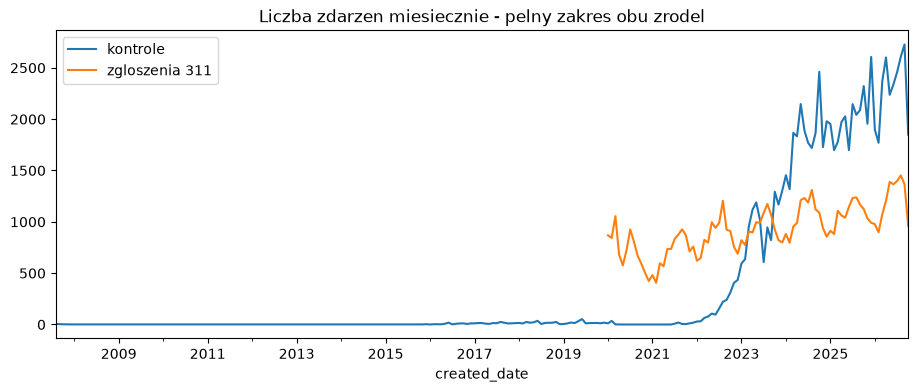

In [84]:
fig, ax = plt.subplots()
inspections.set_index("inspection_date").resample("MS").size().rename("kontrole").plot(ax=ax)
r311.set_index("created_date").resample("MS").size().rename("zgloszenia 311").plot(ax=ax)
ax.set_title("Liczba zdarzen miesiecznie - pelny zakres obu zrodel"); ax.legend()
plt.show()

**Wnioski:**
- **Kontrole:**
  - do 2021 r. jest ich prawie zero, w latach 2022–2023 ich liczba szybko rośnie, a dopiero od 2024 r. stabilizuje się na poziomie ok. 1,7–2,7 tys. miesięcznie;
  - to nie jest realny wzrost liczby kontroli, tylko efekt zasad zbioru: DOHMH publikuje tylko kontrole z ok. 3 lat przed ostatnią kontrolą danego lokalu i tylko dla działających restauracji, więc starsze lata są szczątkowe.
- **Zgłoszenia 311:**
  - mają wyraźną **sezonowość**: szczyt latem (lipiec–sierpień) i dołki zimą;
  - ich liczba rośnie z roku na rok, a w latach 2020–2021 widać spadek związany z pandemią.

Wyznaczenie **wspólnego okresu** obu źródeł. Tylko w nim porównujemy kontrole ze zgłoszeniami.

In [85]:
# wspolny okres: od pierwszego miesiaca, w ktorym OBA zrodla maja pelne dane
def data_start(dates, frac=0.5):
    # poczatek pelnych danych: od tego miesiaca KAZDY miesiac ma >= 50% typowego poziomu
    # (typowy poziom = mediana z ostatnich 24 pelnych miesiecy; stare, rzadkie lata nie zanizaja progu)
    m = dates.dt.to_period("M").value_counts().sort_index()
    m = m.reindex(pd.period_range(m.index.min(), m.index.max(), freq="M"), fill_value=0)
    ok = (m >= frac * m.iloc[-25:-1].median()).iloc[:-1]   # bez ostatniego, niepelnego miesiaca
    bad = ok[~ok]
    return (bad.index[-1] + 1).to_timestamp() if len(bad) else m.index[0].to_timestamp()

COMMON_FROM = max(data_start(inspections["inspection_date"]), data_start(r311["created_date"]))
COMMON_TO = min(inspections["inspection_date"].max(), r311["created_date"].max()).normalize()
print("start inspekcji:", data_start(inspections["inspection_date"]).date(),
      "| start 311:", data_start(r311["created_date"]).date())
print("wspolny okres:", COMMON_FROM.date(), "->", COMMON_TO.date())
print("kontrole przed wspolnym okresem:", (inspections["inspection_date"] < COMMON_FROM).sum(),
      f"({100*(inspections['inspection_date'] < COMMON_FROM).mean():.1f}%)")
print("zgloszenia 311 przed wspolnym okresem:", (r311["created_date"] < COMMON_FROM).sum(),
      f"({100*(r311['created_date'] < COMMON_FROM).mean():.1f}%)")
inspections["inspection_date"].dt.year.value_counts().sort_index()

start inspekcji: 2023-10-01 | start 311: 2021-03-01
wspolny okres: 2023-10-01 -> 2026-10-21
kontrole przed wspolnym okresem: 10876 (13.0%)
zgloszenia 311 przed wspolnym okresem: 36180 (47.4%)


inspection_date
2007       12
2008        6
2009        1
2010        4
2011        2
2012        2
2013        1
2014        4
2015        8
2016       78
2017      158
2018      207
2019      218
2020       47
2021       66
2022     2172
2023    11652
2024    22029
2025    24288
2026    22853
Name: count, dtype: int64

**Wnioski:**
- Funkcja `data_start` uznaje za początek pełnych danych miesiąc, od którego każdy kolejny miesiąc ma co najmniej połowę typowej liczby zdarzeń. Typowa liczba to mediana z ostatnich 24 miesięcy.
- Dla kontroli wychodzi 10.2023, a dla 311 – 03.2021. Wspólny okres to więc **10.2023 – 10.2026**.
- Poza nim zostaje 13% kontroli i 47% zgłoszeń 311. Te zgłoszenia nadal przydają się do analizy trendu i sezonowości samych zgłoszeń.
- Na początku wspólnego okresu (10.2023 – 02.2024) kontroli jest jeszcze ok. 1/3 mniej niż później. Porównania w czasie trzeba więc normalizować, np. zgłoszenia na kontrolę albo na restaurację.

Rozkład zgłoszeń 311 według roku.

In [86]:
r311["created_date"].dt.year.value_counts().sort_index()

created_date
2020     8665
2021     8501
2022    10300
2023    11258
2024    12568
2025    12934
2026    12080
Name: count, dtype: int64

**Wnioski:** liczba zgłoszeń wzrosła z 8,7 tys. (2020) do 12,9 tys. (2025), czyli o ok. 50%. Rok 2026 jest niepełny.

## 8. Możliwości łączenia źródeł
Zbiory nie mają wspólnego identyfikatora restauracji. Sprawdzamy, na ile pokrywają się potencjalne klucze: dzielnica, ZIP i znormalizowany adres.

In [87]:
def overlap(a, b, name):
    a, b = set(a.dropna()), set(b.dropna())
    return {"klucz": name, "unikalne w inspekcjach": len(a), "unikalne w 311": len(b), "wspolne": len(a & b),
            "% kluczy inspekcji obecnych w 311": round(100 * len(a & b) / max(len(a), 1), 1),
            "% kluczy 311 obecnych w inspekcjach": round(100 * len(a & b) / max(len(b), 1), 1)}

def norm_addr(s):
    return s.astype("string").str.upper().str.replace(r"\s+", " ", regex=True).str.strip()

restaurants["address"] = norm_addr(restaurants["building"].fillna("") + " " + restaurants["street"].fillna(""))
r311["address"] = norm_addr(r311["incident_address"])

pd.DataFrame([
    overlap(restaurants["boro"], r311["borough_u"], "borough"),
    overlap(restaurants["zipcode"], r311["incident_zip"], "ZIP"),
    overlap(restaurants["address"], r311["address"], "adres (numer + ulica)"),
])

,klucz,unikalne w inspekcjach,unikalne w 311,wspolne,% kluczy inspekcji obecnych w 311,% kluczy 311 obecnych w inspekcjach
0,borough,6,6,5,83.3,83.3
1,ZIP,254,220,213,83.9,96.8
2,adres (numer + ulica),25633,29632,14627,57.1,49.4


**Wnioski:** **ZIP jest najlepszym kluczem do łączenia**: 97% kodów ZIP z 311 występuje w inspekcjach. Adres pokrywa się tylko w ok. połowie przypadków, więc samo dopasowanie po adresie nie wystarczy. Borough różni się głównie zapisem (wielkość liter oraz `0` vs `Unspecified`).

Porównanie wartości `boro` / `borough` w obu źródłach (różne kodowanie braków: `0` vs `Unspecified`).

In [88]:
pd.concat([insp["boro"].value_counts(dropna=False).rename("inspekcje"),
           r311["borough"].value_counts(dropna=False).rename("311")], axis=1)

,inspekcje,311
Manhattan,108989.0,NaN
Brooklyn,74430.0,NaN
Queens,73836.0,NaN
Bronx,27418.0,NaN
Staten Island,9422.0,NaN
0,311.0,NaN
MANHATTAN,NaN,25986.0
BROOKLYN,NaN,21600.0
QUEENS,NaN,17367.0
BRONX,NaN,7360.0


**Wnioski:** po ujednoliceniu wielkości liter nazwy dzielnic są zgodne. W obu źródłach dominuje Manhattan, a najmniej rekordów ma Staten Island.

Jaka część zgłoszeń 311 ma adres zgodny z adresem restauracji z inspekcji (dopasowanie dokładne).

In [89]:
# ile zgloszen 311 da sie przypisac do konkretnej restauracji po adresie
addr_match = r311["address"].isin(set(restaurants["address"].dropna()))
print(f"zgloszenia 311 z adresem pasujacym do restauracji z inspekcji: {addr_match.mean()*100:.1f}%")
r311.loc[~addr_match, ["incident_address", "incident_zip", "borough", "address_type"]].head(10)

zgloszenia 311 z adresem pasujacym do restauracji z inspekcji: 62.8%


,incident_address,incident_zip,borough,address_type
0,2263 EMMONS AVENUE,11235,BROOKLYN,ADDRESS
3,2484 PITKIN AVENUE,11208,BROOKLYN,ADDRESS
4,4168 WHITE PLAINS ROAD,10466,BRONX,ADDRESS
5,64-17 108 STREET,11375,QUEENS,ADDRESS
7,97-16 101 AVENUE,11416,QUEENS,ADDRESS
9,NaN,<NA>,Unspecified,NaN
13,80 JOHN STREET,10038,MANHATTAN,ADDRESS
14,NaN,<NA>,Unspecified,NaN
15,7405 3 AVENUE,11209,BROOKLYN,ADDRESS
16,NaN,<NA>,Unspecified,NaN


**Wnioski:** 63% zgłoszeń da się przypisać do restauracji po dokładnym adresie. Niedopasowane to głównie zgłoszenia bez adresu (`Unspecified`) oraz adresy zapisane inaczej niż w inspekcjach.

Dopasowanie przestrzenne: dla każdego zgłoszenia szukamy najbliższej restauracji (KD-tree na współrzędnych przeliczonych na metry).

In [90]:
# laczenie przestrzenne: odleglosc zgloszenia 311 do najblizszej restauracji (w metrach)
from scipy.spatial import cKDTree

def to_xy(lat, lon):
    # przyblizona projekcja na metry, wystarczajaca w skali miasta
    return np.c_[lon * 111_320 * np.cos(np.radians(40.7)), lat * 110_540]

rest_ok = restaurants.dropna(subset=["latitude", "longitude"])
rest_ok = rest_ok[(rest_ok["latitude"] != 0) & (rest_ok["longitude"] != 0)]
r_ok = r311.dropna(subset=["latitude", "longitude"])

tree = cKDTree(to_xy(rest_ok["latitude"].values, rest_ok["longitude"].values))
dist, idx = tree.query(to_xy(r_ok["latitude"].values, r_ok["longitude"].values))
r311.loc[r_ok.index, "nearest_camis"] = rest_ok["camis"].values[idx]
r311.loc[r_ok.index, "nearest_dist_m"] = dist

print(pd.Series(dist).describe(percentiles=[.25, .5, .75, .9]).round(1))
for d in (10, 25, 50, 100):
    print(f"zgloszenia w promieniu {d} m od restauracji: {(dist <= d).mean()*100:.1f}%")

count    75087.0
mean        19.3
std         58.4
min          0.1
25%          0.7
50%          0.8
75%          7.5
90%         53.3
max       1784.2
dtype: float64
zgloszenia w promieniu 10 m od restauracji: 77.1%
zgloszenia w promieniu 25 m od restauracji: 84.3%
zgloszenia w promieniu 50 m od restauracji: 89.5%
zgloszenia w promieniu 100 m od restauracji: 94.6%


**Wnioski:** mediana odległości to 0,8 m, co oznacza, że zgłoszenia 311 są geokodowane praktycznie w punkt restauracji. Przy progu **25 m** dopasowujemy 84% zgłoszeń, więc dopasowanie przestrzenne dobrze uzupełnia dopasowanie po adresie.

Rozkład odległości zgłoszenia od najbliższej restauracji – pomaga dobrać próg dopasowania.

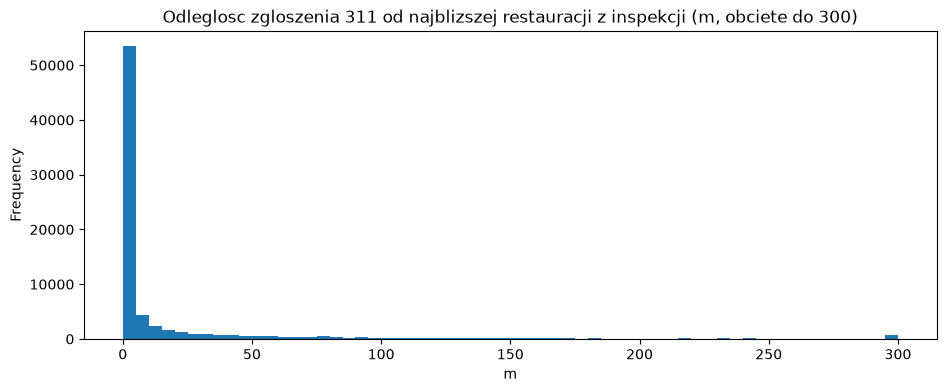

In [91]:
fig, ax = plt.subplots()
pd.Series(dist).clip(upper=300).plot.hist(bins=60, ax=ax)
ax.set_title("Odleglosc zgloszenia 311 od najblizszej restauracji z inspekcji (m, obciete do 300)")
ax.set_xlabel("m"); plt.show()

Próba połączenia na poziomie zagregowanym **ZIP × miesiąc** – docelowa granularność do porównania liczby zgłoszeń z wynikami kontroli.

In [92]:
# proba polaczenia na poziomie ZIP x miesiac (wspolny okres)
ins_c = inspections[inspections["inspection_date"].between(COMMON_FROM, COMMON_TO)]
r_c = r311[r311["created_date"].between(COMMON_FROM, COMMON_TO)]

zip_month = (ins_c.assign(month=ins_c["inspection_date"].dt.to_period("M"))
               .groupby(["zipcode", "month"])
               .agg(n_inspections=("camis", "size"), mean_score=("score", "mean"),
                    n_violations=("n_violations", "sum"))
             .join(r_c.assign(month=r_c["created_date"].dt.to_period("M"))
                     .groupby(["incident_zip", "month"]).size().rename("n_311")
                     .rename_axis(["zipcode", "month"]), how="outer"))
print("komorki ZIP x miesiac:", len(zip_month))
print("tylko inspekcje (brak 311):", zip_month["n_311"].isna().sum())
print("tylko 311 (brak inspekcji):", zip_month["n_inspections"].isna().sum())
zip_month.head(25)

komorki ZIP x miesiac: 6820
tylko inspekcje (brak 311): 780
tylko 311 (brak inspekcji): 375


n_inspections  mean_score  n_violations  n_311
zipcode month                                                  
07002   2024-02            1.0        12.0           3.0    NaN
        2025-04            1.0        12.0           2.0    NaN
07071   2023-10            1.0        28.0           6.0    NaN
        2024-08            1.0        18.0           3.0    NaN
        2025-11            1.0        12.0           2.0    NaN
07074   2024-06            1.0         5.0           1.0    NaN
        2025-09            1.0         3.0           1.0    NaN
07304   2024-10            1.0        12.0           2.0    NaN
        2026-02            1.0        24.0           5.0    NaN
07307   2024-03            1.0        12.0           3.0    NaN
        2024-09            1.0        13.0           2.0    NaN
        2025-03            1.0        27.0           5.0    NaN
        2025-08            1.0        19.0           6.0    NaN
        2025-11            2.0        12.5           7.0    NaN
07627   2024-10            1.0         5.0           3.0    NaN
07631   2025-02            1.0        12.0           2.0    NaN
        2026-06            1.0        41.0           8.0    NaN
        2026-07            1.0        12.0           2.0    NaN
08550   2025-04            1.0       106.0           6.0    NaN
        2025-05            3.0        20.0           3.0    NaN
        2025-08            1.0         7.0           2.0    NaN
08879   2024-10            1.0        10.0           2.0    NaN
10000   2024-05            NaN         NaN           NaN    1.0
        2024-07            1.0         8.0           2.0    NaN
        2025-02            NaN         NaN           NaN    1.0

**Wnioski:**
- We wspólnym okresie mamy 6 820 komórek ZIP × miesiąc. Tylko w 375 są same zgłoszenia, a w 780 same kontrole, więc oba źródła dobrze się pokrywają i łączenie po ZIP × miesiąc jest wykonalne.
- W wielu komórkach jest jednak tylko kilka kontroli. Do porównań średniego wyniku stabilniejszy będzie **ZIP × kwartał**.
- Przed łączeniem trzeba odfiltrować ZIP-y spoza NYC (07xxx i 08xxx to New Jersey) oraz błędne kody, np. `10000`.

## 9. Jakość danych
### Braki
Odsetek brakujących wartości w każdej kolumnie obu zbiorów.

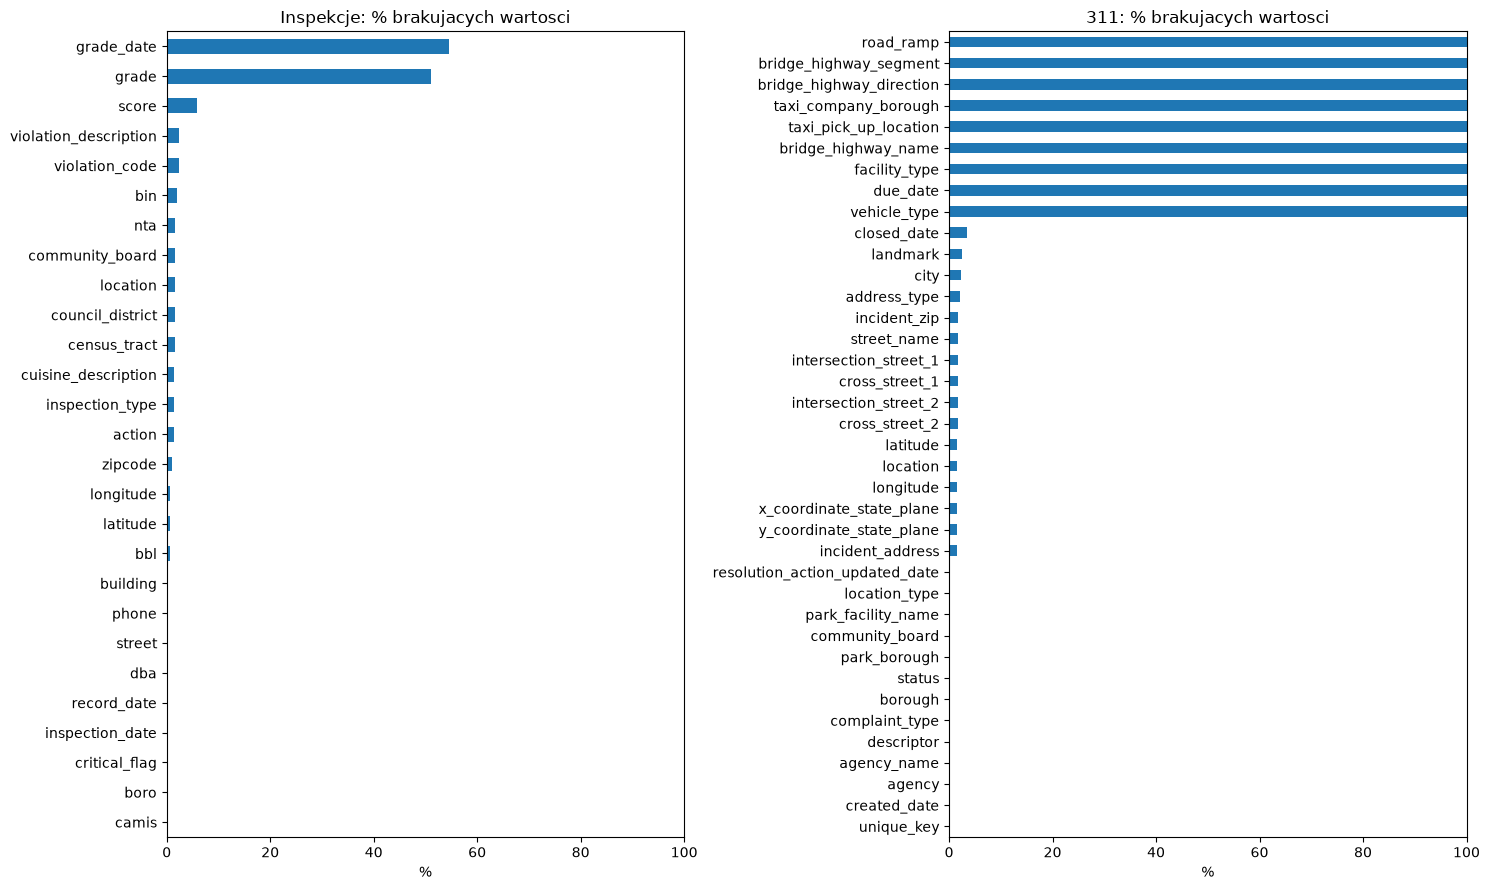

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))
for ax, (name, df) in zip(axes, [("Inspekcje", insp_raw), ("311", r311_raw)]):
    (df.isna().mean() * 100).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{name}: % brakujacych wartosci"); ax.set_xlabel("%"); ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

### Bezużyteczne kolumny

Kolumny 311, które są prawie zawsze puste lub mają jedną wartość (pola dla innych typów zgłoszeń, np. taxi, mosty, parki) – kandydaci do usunięcia.

In [94]:
# kolumny 311 zawsze puste lub z jedna wartoscia (nieprzydatne dla zgloszen restauracyjnych)
useless = pd.DataFrame({"braki_%": (r311_raw.isna().mean() * 100).round(1), "unikalne": r311_raw.nunique()})
useless[(useless["braki_%"] > 95) | (useless["unikalne"] <= 1)]

,braki_%,unikalne
agency,0.0,1
agency_name,0.0,1
complaint_type,0.0,1
facility_type,100.0,0
due_date,100.0,0
vehicle_type,100.0,0
taxi_company_borough,100.0,0
taxi_pick_up_location,100.0,0
bridge_highway_name,100.0,0
bridge_highway_direction,100.0,0


**Wnioski:** 12 kolumn 311 (taxi, mosty, `due_date`, `facility_type` oraz stałe `agency` i `complaint_type`) można usunąć z modelu.

### Duplikaty
Pełne duplikaty, powtórzone naruszenia w tej samej kontroli oraz wielokrotne zgłoszenia 311 tego samego problemu pod tym samym adresem w jednym dniu.

In [95]:
pd.Series({
    "inspekcje: pelne duplikaty wierszy": insp_raw.duplicated().sum(),
    "inspekcje: duplikaty (camis, data, kod naruszenia)":
        insp.dropna(subset=["violation_code"]).duplicated(["camis", "inspection_date", "violation_code"]).sum(),
    "311: pelne duplikaty wierszy": r311_raw.duplicated().sum(),
    "311: duplikaty unique_key": r311["unique_key"].duplicated().sum(),
    "311: to samo (adres, problem, dzien) - wielokrotne zgloszenia":
        r311.assign(d=r311["created_date"].dt.date).dropna(subset=["address"])
            .duplicated(["address", "descriptor", "d"]).sum(),
})

inspekcje: pelne duplikaty wierszy                                217
inspekcje: duplikaty (camis, data, kod naruszenia)                217
311: pelne duplikaty wierszy                                        0
311: duplikaty unique_key                                           0
311: to samo (adres, problem, dzien) - wielokrotne zgloszenia    2432
dtype: int64

**Wnioski:** w inspekcjach jest 217 pełnych duplikatów do usunięcia. W 311 nie ma duplikatów technicznych, ale 2 432 zgłoszenia (3,2%) powtarzają ten sam problem pod tym samym adresem tego samego dnia. To prawdopodobnie kilka osób zgłaszających jedno zdarzenie. Warto liczyć zarówno zgłoszenia, jak i unikalne incydenty.

### Inspekcje - poprawność wartości
Reguły walidacyjne: daty, zakres wyniku, puste oceny, nieprawidłowe dzielnice, ZIP-y i współrzędne.

In [96]:
zip_ok = lambda s: s.str.fullmatch(r"1[01]\d{3}", na=False)   # ZIP-y NYC: 100xx-114xx
bad_xy = lambda df: df["latitude"].fillna(0).eq(0) | df["longitude"].fillna(0).eq(0)

checks_insp = pd.Series({
    "data 1900-01-01 (restauracja jeszcze niekontrolowana)": (insp["inspection_date"].dt.year == 1900).sum(),
    "data inspekcji w przyszlosci": (insp["inspection_date"] > TODAY).sum(),
    "brak score (poza 1900)": (insp["score"].isna() & (insp["inspection_date"].dt.year > 1900)).sum(),
    "score < 0": (insp["score"] < 0).sum(),
    "score > 100": (insp["score"] > 100).sum(),
    "grade pusty": insp["grade"].isna().sum(),
    "grade N/Z/P (brak oceny / w trakcie)": insp["grade"].isin(["N", "Z", "P"]).sum(),
    "boro = '0'": (insp["boro"] == "0").sum(),
    "ZIP pusty lub spoza NYC": (~zip_ok(insp["zipcode"])).sum(),
    "wspolrzedne 0 lub brak": bad_xy(insp).sum(),
    "cuisine pusty": insp["cuisine_description"].isna().sum(),
    "brak kodu naruszenia (poza 1900)": (insp["violation_code"].isna() & (insp["inspection_date"].dt.year > 1900)).sum(),
})
q_insp = pd.DataFrame({"liczba": checks_insp, "% wierszy": (100 * checks_insp / len(insp)).round(2)})
q_insp

,liczba,% wierszy
data 1900-01-01 (restauracja jeszcze niekontrolowana),3917,1.33
data inspekcji w przyszlosci,0,0.00
brak score (poza 1900),13472,4.58
score < 0,0,0.00
score > 100,2040,0.69
grade pusty,150179,51.01
grade N/Z/P (brak oceny / w trakcie),16256,5.52
boro = '0',311,0.11
ZIP pusty lub spoza NYC,3273,1.11
wspolrzedne 0 lub brak,4751,1.61


**Wnioski:**
- Większość problemów w inspekcjach dotyczy braku oceny (`grade`), a nie błędnych wartości.
- 2 040 wierszy ma score > 100. Takie wyniki są możliwe przy bardzo złych kontrolach, więc w analizach warto stosować medianę lub obcinanie wyników.
- Pusty `cuisine` dotyczy prawie wyłącznie restauracji, które nie miały jeszcze kontroli (data `1900-01-01`).

Rozkład ocen na poziomie wierszy i kontroli. Oceny `N`, `Z`, `P` oznaczają brak oceny lub ocenę w trakcie.

In [97]:
pd.concat([insp["grade"].value_counts(dropna=False).rename("wiersze"),
           inspections["grade"].value_counts(dropna=False).rename("kontrole")], axis=1)

,wiersze,kontrole
grade,,
NaN,150179,28939
A,97405,44412
B,17745,4258
C,12821,2201
N,10234,2204
Z,5315,1268
P,707,526


**Wnioski:** na poziomie kontroli 53% ma ocenę A, 5% B, 2,6% C, a 35% nie ma oceny wcale. Ocena C jest rzadka, więc mapy i rankingi oparte tylko na liczbie ocen C będą „rzadkie”. Lepiej pokazywać średni score lub % kontroli z wynikiem ≥ 28.

Ocena A/B/C jest przyznawana tylko przy części typów kontroli – sprawdzamy, których.

In [98]:
# typ kontroli a obecnosc oceny - ocena przysluguje tylko przy czesci kontroli
(inspections.assign(ma_grade=inspections["grade"].isin(["A", "B", "C"]))
    .groupby("inspection_type")["ma_grade"].agg(["size", "mean"])
    .rename(columns={"size": "kontrole", "mean": "% z ocena A/B/C"})
    .sort_values("kontrole", ascending=False).head(20).round(3))

,kontrole,% z ocena A/B/C
inspection_type,,
Cycle Inspection / Initial Inspection,45355,0.583
Cycle Inspection / Re-inspection,16854,0.940
Pre-permit (Operational) / Initial Inspection,9819,0.456
Pre-permit (Operational) / Re-inspection,3015,0.904
Administrative Miscellaneous / Initial Inspection,2825,0.235
Inter-Agency Task Force / Initial Inspection,1271,0.000
Cycle Inspection / Reopening Inspection,1250,0.166
Pre-permit (Non-operational) / Initial Inspection,897,0.000
Pre-permit (Operational) / Reopening Inspection,451,0.086


**Wnioski:** ocenę dostaje głównie kontrola cykliczna (94% re-inspekcji i 58% pierwszych kontroli). Kontrole Task Force, kontrole zgodności i pre-permit nieoperacyjne nie mają ocen. Brak oceny wynika więc z procedury, a nie z błędu danych.

Spójność oceny z wynikiem punktowym według progów DOHMH (A: 0–13, B: 14–27, C: 28+).

In [99]:
# spojnosc grade vs score (A: 0-13, B: 14-27, C: 28+)
def expected_grade(s):
    if pd.isna(s): return np.nan
    return "A" if s <= 13 else ("B" if s <= 27 else "C")

g = inspections[inspections["grade"].isin(["A", "B", "C"])].copy()
g["grade_expected"] = g["score"].apply(expected_grade)
mism = (g["grade"] != g["grade_expected"])
print(f"kontrole z ocena niezgodna z progami score: {mism.sum()} z {len(g)} ({100*mism.mean():.1f}%)")
pd.crosstab(g["grade"], g["grade_expected"], margins=True)

kontrole z ocena niezgodna z progami score: 271 z 50871 (0.5%)


grade_expected,A,B,C,All
grade,,,,
A,44411,1,0,44412
B,10,4234,14,4258
C,240,6,1955,2201
All,44661,4241,1969,50871


**Wnioski:** ocena i wynik są zgodne w 99,5% kontroli. Niezgodności to prawie wyłącznie ocena C przy niskim wyniku podczas *Reopening Inspection*, czyli ponownego otwarcia lokalu po zamknięciu.

Przykłady niezgodności między oceną a wynikiem.

In [100]:
# przyklady niezgodnosci (czesto: ocena po re-inspekcji, a score z pierwszej kontroli)
g.loc[mism, ["camis", "dba", "inspection_date", "inspection_type", "score", "grade", "grade_expected"]].head(10)

,camis,dba,inspection_date,inspection_type,score,grade,grade_expected
136,40365546,REBEN LUNCHEONETTE,2024-03-05,Cycle Inspection / Reopening Inspection,3.0,C,A
1322,40393832,GLEN PATRICK'S PUB,2025-02-18,Cycle Inspection / Reopening Inspection,0.0,C,A
1374,40394761,E & L BAKERY & COFFEE SHOP,2025-12-05,Cycle Inspection / Reopening Inspection,3.0,C,A
1437,40395597,ELMHURST FAMOUS PIZZA,2022-09-19,Cycle Inspection / Re-inspection,35.0,B,C
2192,40512074,ALFONSO'S PASTRY SHOPPE,2023-01-05,Cycle Inspection / Reopening Inspection,2.0,C,A
3211,40618281,PASQUALE'S RIGOLETTO RESTAURANT,2025-03-14,Cycle Inspection / Reopening Inspection,2.0,C,A
3514,40678995,TANDOORI FOOD & BAKERY,2024-09-26,Cycle Inspection / Reopening Inspection,3.0,C,A
3721,40714228,NEW SOLDIERS RESTAURANT,2024-08-29,Cycle Inspection / Reopening Inspection,3.0,C,A
3972,40739276,LATIN AMERICAN RESTAURANT,2024-09-04,Cycle Inspection / Reopening Inspection,2.0,C,A
4291,40796758,PLYMOUTH CAFE,2023-08-08,Cycle Inspection / Reopening Inspection,5.0,C,A


Rozkład wyniku kontroli z zaznaczonymi progami ocen.

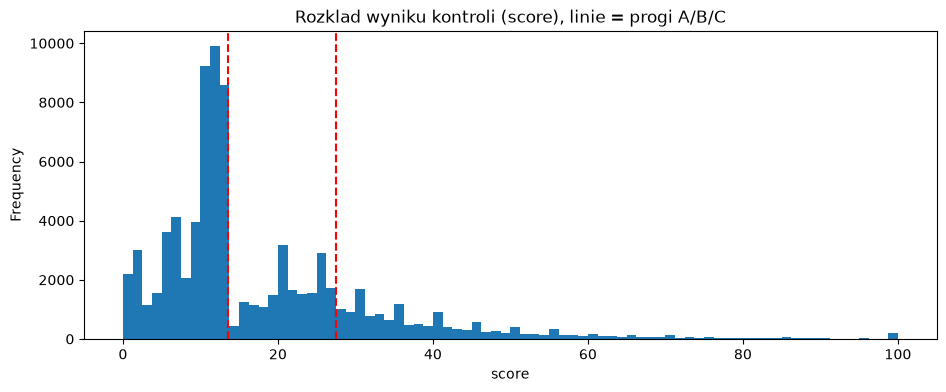

In [101]:
fig, ax = plt.subplots()
inspections["score"].dropna().clip(upper=100).plot.hist(bins=80, ax=ax)
for x in (13.5, 27.5): ax.axvline(x, color="red", ls="--")
ax.set_title("Rozklad wyniku kontroli (score), linie = progi A/B/C"); ax.set_xlabel("score")
plt.show()

**Wnioski:** wyniki wyraźnie skupiają się na 10–13 pkt, tuż poniżej progu oceny A, a zaraz za progiem (14 pkt) jest gwałtowny spadek. To typowy efekt progu: wyniki „przyklejają się” do granicy A. Widać też mniejsze skupienia tuż poniżej progu C (27 pkt) oraz przy 100 pkt.

### 311 – poprawność wartości
Reguły walidacyjne: daty zamknięcia, czas obsługi, zgodność statusu z datą zamknięcia, lokalizacja i typ miejsca.

In [102]:
r311["resolution_d"] = (r311["closed_date"] - r311["created_date"]).dt.total_seconds() / 86400

checks_311 = pd.Series({
    "brak closed_date": r311["closed_date"].isna().sum(),
    "closed_date < created_date": (r311["resolution_d"] < 0).sum(),
    "closed_date = created_date": (r311["resolution_d"] == 0).sum(),
    "czas obslugi > 365 dni": (r311["resolution_d"] > 365).sum(),
    "closed_date w przyszlosci": (r311["closed_date"] > TODAY + pd.Timedelta(days=1)).sum(),
    "status Closed bez closed_date": ((r311["status"] == "Closed") & r311["closed_date"].isna()).sum(),
    "status inny niz Closed, ale jest closed_date": ((r311["status"] != "Closed") & r311["closed_date"].notna()).sum(),
    "borough Unspecified/pusty": (r311["borough"].isna() | r311["borough_u"].eq("UNSPECIFIED")).sum(),
    "ZIP pusty lub spoza NYC": (~zip_ok(r311["incident_zip"])).sum(),
    "brak adresu": r311["incident_address"].isna().sum(),
    "wspolrzedne 0 lub brak": bad_xy(r311).sum(),
    "location_type inny niz restauracja": (~r311["location_type"].fillna("").str.contains("Restaurant", case=False)).sum(),
})
q_311 = pd.DataFrame({"liczba": checks_311, "% wierszy": (100 * checks_311 / len(r311)).round(2)})
q_311

,liczba,% wierszy
brak closed_date,2627,3.44
closed_date < created_date,0,0.00
closed_date = created_date,0,0.00
czas obslugi > 365 dni,31708,41.55
closed_date w przyszlosci,0,0.00
status Closed bez closed_date,0,0.00
"status inny niz Closed, ale jest closed_date",3,0.00
borough Unspecified/pusty,1202,1.58
ZIP pusty lub spoza NYC,1350,1.77
brak adresu,1203,1.58


**Wnioski:** 41,6% zgłoszeń ma czas obsługi powyżej roku, a 3,4% jest wciąż otwartych (*In Progress*). Ok. 10% zgłoszeń nie dotyczy restauracji (`location_type`). Lokalizacji (ZIP, adresu, współrzędnych) brakuje tylko w ok. 1,6–1,8% zgłoszeń.

Statusy zgłoszeń.

In [103]:
r311["status"].value_counts(dropna=False)

status
Closed         73676
In Progress     2627
Unspecified        3
Name: count, dtype: int64

Typy lokalizacji – czy wszystkie zgłoszenia faktycznie dotyczą restauracji.

In [104]:
r311["location_type"].value_counts(dropna=False)

location_type
Restaurant/Bar/Deli/Bakery              68801
Other (Explain Below)                    5671
Catering Service                          385
Other (explain in Complaint Details)      285
Residence                                 233
Cafeteria - College/University            129
Senior Center                             118
Soup Kitchen                               99
Restaurant                                 97
1-2 Family Dwelling                        92
Street Fair Vendor                         90
Cafeteria - Private School                 56
Permanent Food Stand                       43
Cafeteria - Public School                  35
Store                                      28
Cafeteria - Private                        27
Food Cart Vendor                           20
Commercial Building                        20
Other                                      15
Correctional Facility - City               12
Correctional Facility - State               9
Catering Hall       

**Wnioski:** 90% zgłoszeń dotyczy restauracji, barów, delikatesów i piekarni. Pozostałe to m.in. catering, stołówki, domy prywatne i food trucki. W analizach łączonych z inspekcjami restauracji warto je odfiltrować.

Wykrywanie masowego zamykania zgłoszeń (wiele zgłoszeń z identyczną datą zamknięcia) – zniekształca czas obsługi.

In [105]:
# masowe zamykanie zgloszen: ta sama data zamkniecia co do sekundy w wielu zgloszeniach
bulk = r311["closed_date"].value_counts()
bulk = bulk[bulk >= 20]
print(f"daty zamkniecia wspolne dla >= 20 zgloszen: {len(bulk)}, obejmuja {bulk.sum()} zgloszen "
      f"({100*bulk.sum()/len(r311):.1f}%)")
bulk.head(10)

daty zamkniecia wspolne dla >= 20 zgloszen: 6, obejmuja 140 zgloszen (0.2%)


closed_date
2025-06-25 00:00:05    28
2025-06-16 00:00:07    25
2025-06-23 00:00:06    24
2025-05-24 00:00:03    23
2025-05-05 08:24:09    20
2025-06-26 00:00:06    20
Name: count, dtype: int64

**Wnioski:** test „ta sama sekunda” znajduje tylko 140 zgłoszeń, ale jest zbyt restrykcyjny. W podglądzie danych widać, że zgłoszenia z 2020 r. zamykano seriami 3 czerwca 2024 (w odstępach kilku sekund). Masowe zamknięcia lepiej wykrywać po **dniu** zamknięcia.

Rozkład czasu obsługi zgłoszenia (tylko dodatnie wartości).

count    73679.00
mean       476.70
std        484.78
min          0.01
50%        251.25
75%        816.29
90%       1316.80
99%       1585.94
max       1615.46
Name: resolution_d, dtype: float64


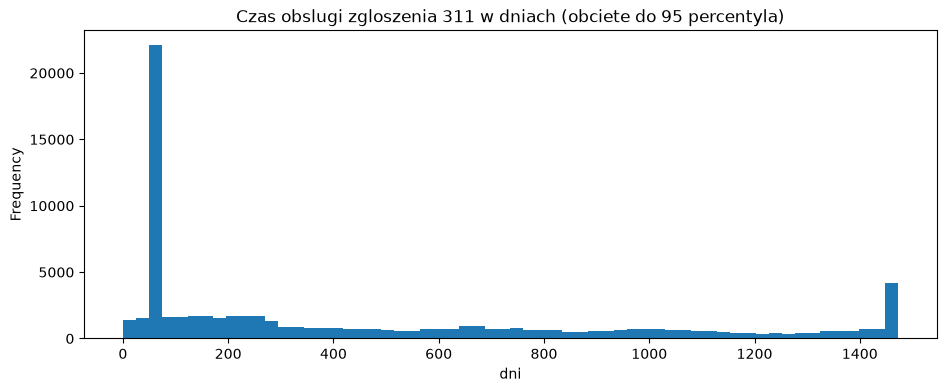

In [106]:
ok = r311.loc[r311["resolution_d"] > 0, "resolution_d"]
print(ok.describe(percentiles=[.5, .75, .9, .99]).round(2))
fig, ax = plt.subplots()
ok.clip(upper=ok.quantile(.95)).plot.hist(bins=60, ax=ax)
ax.set_title("Czas obslugi zgloszenia 311 w dniach (obciete do 95 percentyla)"); ax.set_xlabel("dni")
plt.show()

**Wnioski:** rozkład ma dwa sztuczne szczyty:
- ok. **60 dni**: najpewniej standardowy termin administracyjnego zamknięcia,
- ok. **1 450–1 470 dni**: stare zgłoszenia zamknięte hurtowo.

Średnia (477 dni) i mediana (251 dni) nie opisują więc realnego czasu reakcji.

Czas obsługi według roku zgłoszenia – czy starsze zgłoszenia były zamykane z dużym opóźnieniem.

In [107]:
# mediana czasu obslugi wg roku zgloszenia - czy stare zgloszenia byly zamykane z opoznieniem
r311[r311["resolution_d"] >= 0].groupby(r311["created_date"].dt.year)["resolution_d"].agg(["count", "median", "mean"]).round(1)

,count,median,mean
created_date,,,
2020,8665,1440.9,1405.1
2021,8501,1042.0,1049.8
2022,10300,692.2,697.6
2023,11258,331.5,336.1
2024,12512,133.7,143.0
2025,12934,60.0,56.6
2026,9509,60.0,56.0


**Wnioski:** mediana spada z 1 441 dni (2020) do 60 dni (2025–2026). To nie efekt poprawy obsługi, tylko zaległości zamykane z opóźnieniem. Czas obsługi można sensownie analizować tylko dla zgłoszeń od 2025 r., a i wtedy jest to raczej termin administracyjny niż czas reakcji.

### Spójność lokalizacji
Czy dzielnica zgadza się z dominującą dzielnicą dla danego kodu ZIP.

In [108]:
def zip_boro_mismatch(df, zip_col, boro_col):
    d = df[[zip_col, boro_col]].dropna()
    d = d[zip_ok(d[zip_col]) & ~d[boro_col].isin(["0", "UNSPECIFIED"])]
    dominant = d.groupby(zip_col)[boro_col].agg(lambda s: s.mode().iloc[0])
    m = d[boro_col] != d[zip_col].map(dominant)
    return m.sum(), len(d)

for name, df, z, b in [("inspekcje", insp, "zipcode", "boro_u"), ("311", r311, "incident_zip", "borough_u")]:
    m, n = zip_boro_mismatch(df, z, b)
    print(f"{name}: {m} z {n} wierszy ma borough inny niz dominujacy dla ZIP ({100*m/max(n,1):.2f}%)")

inspekcje: 7 z 291010 wierszy ma borough inny niz dominujacy dla ZIP (0.00%)
311: 2 z 74954 wierszy ma borough inny niz dominujacy dla ZIP (0.00%)


**Wnioski:** ZIP i dzielnica są w pełni spójne (niezgodności < 0,01%), więc ZIP można bezpiecznie przypisywać do dzielnicy w wymiarze lokalizacji.

Czy brakujące dzielnice (`Unspecified` w 311, `0` w inspekcjach) da się uzupełnić na podstawie ZIP.

In [109]:
# czy 'Unspecified' w 311 i '0' w inspekcjach da sie uzupelnic z ZIP
zip2boro = (r311[~r311["borough_u"].eq("UNSPECIFIED")].dropna(subset=["incident_zip"])
            .groupby("incident_zip")["borough_u"].agg(lambda s: s.mode().iloc[0]))
uns = r311["borough_u"].eq("UNSPECIFIED")
print(f"311 Unspecified: {uns.sum()}, mozliwe do uzupelnienia z ZIP: {r311.loc[uns, 'incident_zip'].isin(zip2boro.index).sum()}")
zero = insp["boro"].eq("0")
print(f"inspekcje boro='0': {zero.sum()}, mozliwe do uzupelnienia z ZIP: {insp.loc[zero, 'zipcode'].isin(zip2boro.index).sum()}")

311 Unspecified: 1202, mozliwe do uzupelnienia z ZIP: 2
inspekcje boro='0': 311, mozliwe do uzupelnienia z ZIP: 43


**Wnioski:** zgłoszeń `Unspecified` praktycznie nie da się uzupełnić z ZIP (2 z 1 202), bo nie mają żadnej lokalizacji. Należy je wykluczyć z analiz przestrzennych (1,6% zgłoszeń). W inspekcjach da się uzupełnić tylko 43 z 311 wierszy z `boro = '0'`.

## 10. Wymiary kategoryczne
### Typ kuchni
Liczba kategorii i najczęstsze typy kuchni.

In [110]:
print("kategorie kuchni:", insp["cuisine_description"].nunique())
restaurants["cuisine"].value_counts(dropna=False).head(25)

kategorie kuchni: 90


cuisine
American                          4804
NaN                               3919
Chinese                           2257
Coffee/Tea                        2208
Pizza                             1601
Latin American                    1116
Mexican                           1113
Japanese                          1055
Italian                           1010
Bakery Products/Desserts           929
Chicken                            742
Caribbean                          732
Other                              544
Donuts                             542
Juice, Smoothies, Fruit Salads     537
Hamburgers                         499
Asian/Asian Fusion                 463
Spanish                            458
Sandwiches                         453
Korean                             425
Frozen Desserts                    389
Thai                               345
Jewish/Kosher                      335
Indian                             319
Mediterranean                      318
Name: count, dtyp

Najrzadsze typy kuchni – kandydaci do grupowania w kategorię „inne”.

In [111]:
restaurants["cuisine"].value_counts().tail(15)

cuisine
Indonesian                   8
Fruits/Vegetables            8
Nuts/Confectionary           8
Not Listed/Not Applicable    8
Cajun                        7
Lebanese                     7
Southwestern                 6
Iranian                      5
Czech                        4
Creole/Cajun                 4
Polynesian                   2
Haute Cuisine                2
Basque                       2
Chilean                      2
Chimichurri                  1
Name: count, dtype: int64

**Wnioski:** 90 kategorii kuchni z długim ogonem (wiele kategorii ma kilka lokali). Do dashboardu warto pogrupować kuchnie i kategorie z małą liczbą restauracji przenieść do „Inne”, a w porównaniach ustawić minimalną liczbę kontroli.

### Naruszenia
Flaga naruszenia krytycznego i najczęstsze kody naruszeń.

In [112]:
insp["critical_flag"].value_counts(dropna=False)

critical_flag
Critical          153991
Not Critical      131621
Not Applicable      8794
Name: count, dtype: int64

In [113]:
insp["violation_code"].value_counts().head(15)

violation_code
10F    41026
08A    25059
06C    18969
10B    18892
02G    18857
06D    18437
02B    15355
04L    13772
04N    11357
04A     7677
10G     7417
04H     6250
05D     5497
06F     5353
06E     5131
Name: count, dtype: int64

**Wnioski:** 52% naruszeń jest krytycznych. Wśród najczęstszych kodów dominują stan powierzchni i wyposażenia (10F, 10B), zabezpieczenie przed szkodnikami i ich obecność (08A, 04L – myszy, 04N – muchy), ochrona żywności (06C, 06D) oraz temperatura przechowywania (02G, 02B).

### Zgłoszenia 311
Typy problemów (`descriptor`) i agencje obsługujące zgłoszenia.

In [114]:
r311["descriptor"].value_counts(dropna=False)

descriptor
Rodents/Insects/Garbage          24894
Food Spoiled                      6211
Pet/Animal                        5471
Bare Hands in Contact w/ Food     5393
Letter Grading                    4815
Food Contaminated                 4379
No Permit or License              3670
Food Worker Hygiene               2928
Food Contains Foreign Object      2811
Kitchen/Food Prep Area            2564
Food Temperature                  2032
Toilet Facility                   2027
Odor                              1968
Food Protection                   1551
Food Preparation Location          859
Permit/License/Certificate         668
Handwashing                        610
Dishwashing/Utensils               568
Facility Construction              492
Food Worker Activity               471
Food Worker Illness                304
Allergy Information                285
Ventilation                        276
Sewage                             229
Toxic Chemical/Material            190
Plumbing      

**Wnioski:**
- Najczęstszy problem zgłaszany przez mieszkańców to szkodniki i śmieci (*Rodents/Insects/Garbage*, 33% zgłoszeń). To dobrze pokrywa się z częstymi naruszeniami dotyczącymi szkodników.
- Ok. 18% zgłoszeń dotyczy jakości jedzenia (zepsute, skażone, ciało obce).
- Ok. 12% to sprawy formalne (ocena, licencja).
- Wszystkie zgłoszenia obsługuje DOHMH, więc agencja nie jest użytecznym wymiarem (patrz profil pól).

## 11. Współrzędne i mapa
Sprawdzenie, czy współrzędne mieszczą się w granicach NYC, oraz wstępna wizualizacja: restauracje według ostatniej oceny i lokalizacje zgłoszeń 311.

restauracje z poprawnymi wspolrzednymi: 97.4%
zgloszenia 311 z poprawnymi wspolrzednymi: 98.4%


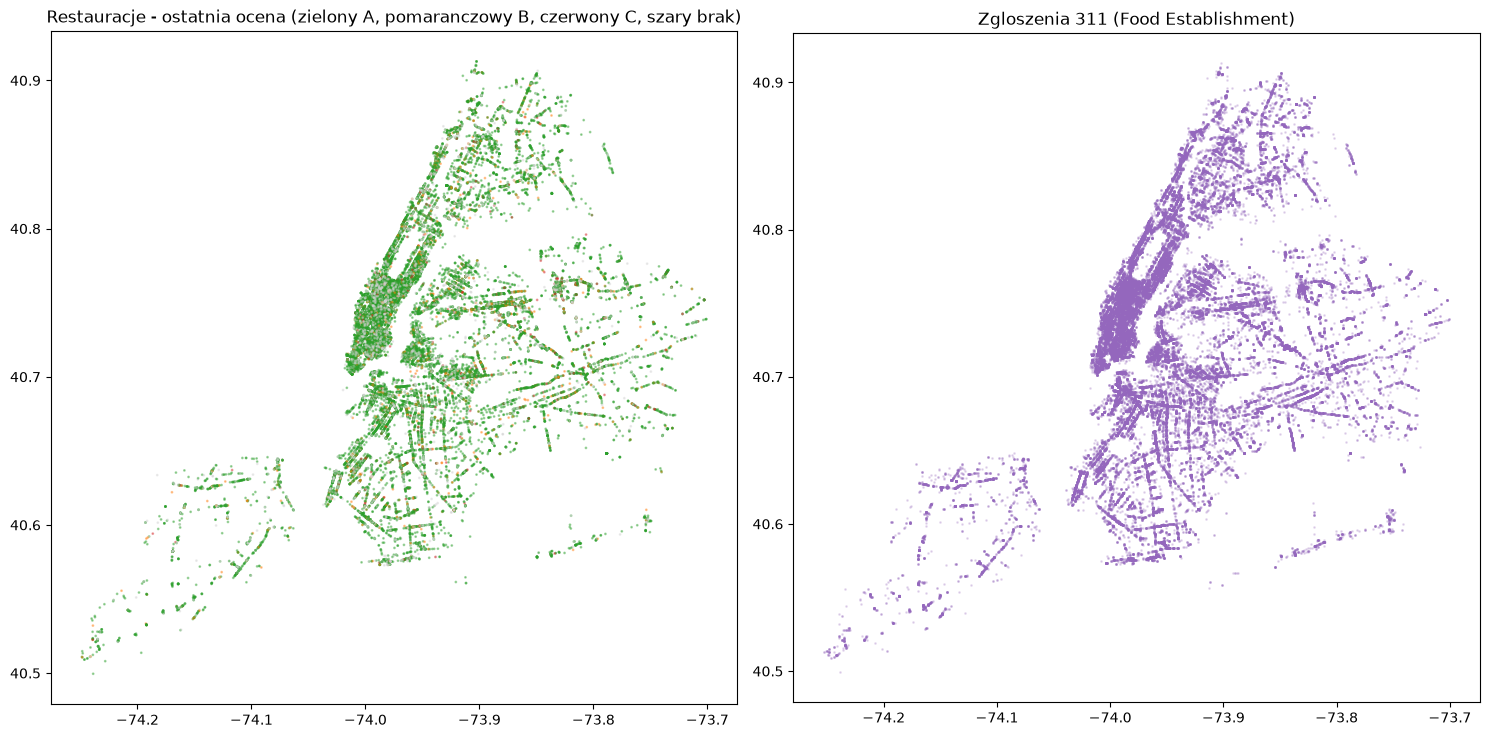

In [115]:
NYC_LAT, NYC_LON = (40.49, 40.92), (-74.27, -73.68)
in_nyc = lambda df: df["latitude"].between(*NYC_LAT) & df["longitude"].between(*NYC_LON)

print(f"restauracje z poprawnymi wspolrzednymi: {100*in_nyc(restaurants).mean():.1f}%")
print(f"zgloszenia 311 z poprawnymi wspolrzednymi: {100*in_nyc(r311).mean():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
last = inspections.sort_values("inspection_date").groupby("camis").last()
last = last[in_nyc(last)]
axes[0].scatter(last["longitude"], last["latitude"], s=1, alpha=.4,
                c=last["grade"].map({"A": "tab:green", "B": "tab:orange", "C": "tab:red"}).fillna("lightgray"))
axes[0].set_title("Restauracje - ostatnia ocena (zielony A, pomaranczowy B, czerwony C, szary brak)")
p = r311[in_nyc(r311)]
axes[1].scatter(p["longitude"], p["latitude"], s=1, alpha=.2, c="tab:purple")
axes[1].set_title("Zgloszenia 311 (Food Establishment)")
for ax in axes: ax.set_aspect(1.3)
plt.tight_layout(); plt.show()

**Wnioski:** ponad 97% rekordów ma poprawne współrzędne, więc dane dobrze nadają się do map. Rozkład zgłoszeń 311 niemal dokładnie odwzorowuje gęstość restauracji (najwięcej na Manhattanie). Porównania obszarów muszą więc być **znormalizowane**, np. jako zgłoszenia na 100 restauracji. Restauracje z oceną C są rozproszone i nie tworzą wyraźnych skupisk.

Zgłoszenia 311 ze współrzędnymi poza NYC lub bez współrzędnych.

In [116]:
r311.loc[~in_nyc(r311), ["unique_key", "incident_address", "incident_zip", "borough", "latitude", "longitude"]].head()

,unique_key,incident_address,incident_zip,borough,latitude,longitude
9,47673159,NaN,<NA>,Unspecified,NaN,NaN
14,47673156,NaN,<NA>,Unspecified,NaN,NaN
16,47667228,NaN,<NA>,Unspecified,NaN,NaN
21,47674962,NaN,<NA>,Unspecified,NaN,NaN
40,47678770,NaN,<NA>,Unspecified,NaN,NaN


## 12. Podsumowanie problemów i decyzje
Zestawienie wykrytych problemów jakości danych z liczbą rekordów i decyzją, jak je obsłużyć w dalszej analizie.

In [117]:
n_i, n_r = len(insp), len(r311)
pct = lambda n, d: round(100 * n / max(d, 1), 2)
row = lambda src, prob, n, d, dec: [src, prob, int(n), pct(n, d) if d else None, dec]

summary = pd.DataFrame([
    row("inspekcje", "1 wiersz = 1 naruszenie, nie kontrola", len(insp) - len(inspections), None,
        "agregacja do (camis, inspection_date)"),
    row("inspekcje", "data 1900-01-01 (niekontrolowane)", checks_insp.iloc[0], n_i, "wykluczyc z analiz kontroli"),
    row("inspekcje", "brak oceny (grade pusty)", checks_insp["grade pusty"], n_i,
        "oceny tylko dla kontroli z grade; jako glowna miare uzyc score"),
    row("inspekcje", "grade N/Z/P", checks_insp["grade N/Z/P (brak oceny / w trakcie)"], n_i, "osobna kategoria 'w trakcie'"),
    row("inspekcje", "grade niezgodny z progami score (kontrole)", mism.sum(), len(g),
        "uwzglednic re-inspekcje; porownywac score, nie grade"),
    row("inspekcje", "boro = '0'", checks_insp["boro = '0'"], n_i, "uzupelnic z ZIP"),
    row("inspekcje", "ZIP pusty/spoza NYC", checks_insp["ZIP pusty lub spoza NYC"], n_i, "uzupelnic ze wspolrzednych lub wykluczyc"),
    row("inspekcje", "brak wspolrzednych", checks_insp["wspolrzedne 0 lub brak"], n_i, "pominac na mapach"),
    row("inspekcje", "kontrole sprzed wspolnego okresu z 311", (inspections["inspection_date"] < COMMON_FROM).sum(),
        len(inspections), "analiza laczona tylko od COMMON_FROM"),
    row("311", "brak closed_date", checks_311["brak closed_date"], n_r, "otwarte zgloszenia - osobno"),
    row("311", "czas obslugi > 365 dni", checks_311["czas obslugi > 365 dni"], n_r,
        "sprawdzic masowe zamkniecia; mediana zamiast sredniej"),
    row("311", "borough Unspecified", checks_311["borough Unspecified/pusty"], n_r, "uzupelnic z ZIP"),
    row("311", "ZIP pusty/spoza NYC", checks_311["ZIP pusty lub spoza NYC"], n_r, "uzupelnic ze wspolrzednych"),
    row("311", "brak wspolrzednych", checks_311["wspolrzedne 0 lub brak"], n_r, "pominac na mapach"),
    row("311", "location_type inny niz restauracja", checks_311["location_type inny niz restauracja"], n_r,
        "zdecydowac: zostawic czy odfiltrowac"),
    row("311", "puste kolumny (taxi, bridge, park...)", len(useless), None, "usunac z modelu"),
    row("laczenie", "brak wspolnego ID restauracji i BBL w 311", 0, None,
        "laczenie po ZIP x miesiac; restauracja przez adres / najblizszy punkt"),
    row("laczenie", "zgloszenia 311 bez pasujacego adresu restauracji", (~addr_match).sum(), n_r,
        "dopasowanie przestrzenne (np. <= 25 m)"),
], columns=["zrodlo", "problem", "liczba", "% rekordow", "decyzja"])
summary

,zrodlo,problem,liczba,% rekordow,decyzja
0,inspekcje,"1 wiersz = 1 naruszenie, nie kontrola",210598,NaN,"agregacja do (camis, inspection_date)"
1,inspekcje,data 1900-01-01 (niekontrolowane),3917,1.33,wykluczyc z analiz kontroli
2,inspekcje,brak oceny (grade pusty),150179,51.01,oceny tylko dla kontroli z grade; jako glowna miare uzyc score
3,inspekcje,grade N/Z/P,16256,5.52,osobna kategoria 'w trakcie'
4,inspekcje,grade niezgodny z progami score (kontrole),271,0.53,"uwzglednic re-inspekcje; porownywac score, nie grade"
5,inspekcje,boro = '0',311,0.11,uzupelnic z ZIP
6,inspekcje,ZIP pusty/spoza NYC,3273,1.11,uzupelnic ze wspolrzednych lub wykluczyc
7,inspekcje,brak wspolrzednych,4751,1.61,pominac na mapach
8,inspekcje,kontrole sprzed wspolnego okresu z 311,10876,12.98,analiza laczona tylko od COMMON_FROM
9,311,brak closed_date,2627,3.44,otwarte zgloszenia - osobno


## Wnioski końcowe

**Zakres i granulacja**
- Zgłoszenia 311 są kompletne od 2020 r. Inspekcje formalnie sięgają 2007 r., ale zbiór DOHMH zawiera tylko kontrole z ok. 3 lat przed ostatnią kontrolą lokalu i tylko dla działających restauracji. W praktyce dane są pełne dopiero od ok. 10.2023.
- Porównania między źródłami robimy wyłącznie we **wspólnym okresie 10.2023 – 10.2026**. Pełny zakres 311 wykorzystujemy do analizy trendu i sezonowości zgłoszeń.
- Ograniczenie źródła: zamknięte restauracje znikają z danych inspekcji, więc obraz jest lekko „za dobry”. Brakuje części lokali o najgorszych wynikach, które zostały zamknięte.
- Zbiór inspekcji ma jeden wiersz na naruszenie. Analizujemy go na dwóch poziomach: **kontroli** (83,8 tys., miary: score, ocena, liczba naruszeń) i **naruszenia** (typy naruszeń).

**Jakość danych**
- Dane są ogólnie dobrej jakości: lokalizacja jest prawie kompletna (ponad 97% poprawnych współrzędnych), ZIP i dzielnica są spójne, a ocena zgadza się z wynikiem w 99,5% kontroli.
- Ocena A/B/C jest dostępna tylko dla ok. 60% kontroli, i to z przyczyn proceduralnych. Główną miarą powinien być **score**, a ocena miarą pomocniczą.
- Wyniki kontroli skupiają się tuż pod progiem oceny A. Średni score należy interpretować ostrożnie i uzupełniać o % wyników ≥ 14 i ≥ 28.
- **Czas obsługi zgłoszeń 311 jest niewiarygodny** jako miara reakcji, bo jest zniekształcony przez hurtowe zamykanie starych zgłoszeń i standardowe 60 dni. Można go pokazywać tylko dla 2025+ i z odpowiednim komentarzem.
- Do usunięcia lub odfiltrowania: 217 duplikatów inspekcji, restauracje z datą `1900-01-01`, ZIP-y spoza NYC, 12 pustych lub stałych kolumn 311, zgłoszenia bez lokalizacji (ok. 1,6%). Opcjonalnie także zgłoszenia, które nie dotyczą restauracji (ok. 10%).

**Łączenie źródeł**
- Nie ma wspólnego identyfikatora restauracji. Najpewniejszym kluczem jest **ZIP** (97% ZIP-ów z 311 występuje w inspekcjach).
- We wspólnym okresie oba źródła pokrywają się dobrze na poziomie ZIP × miesiąc. Do porównań wyników stabilniejszy jest **ZIP × kwartał**.
- Przypisanie zgłoszenia do konkretnej restauracji jest możliwe dla ok. 84% zgłoszeń: najpierw po dokładnym adresie (63%), potem po najbliższym punkcie w promieniu 25 m.
- Liczbę zgłoszeń trzeba normalizować liczbą restauracji w obszarze, bo zgłoszenia koncentrują się tam, gdzie jest najwięcej lokali.

**Pierwsze obserwacje merytoryczne**
- Zgłoszenia 311 rosną z roku na rok i mają wyraźny szczyt latem.
- Mieszkańcy najczęściej zgłaszają szkodniki i śmieci, a szkodniki są też jednymi z najczęstszych naruszeń w kontrolach. To wspiera hipotezę, że 311 może być sygnałem ostrzegawczym, ale trzeba to sprawdzić na danych połączonych.
- Na mapie restauracje z oceną C nie tworzą wyraźnych skupisk, więc różnice między obszarami trzeba będzie badać na miarach zagregowanych (średni score, % naruszeń krytycznych), a nie na samych ocenach C.